# Solver settings, convergence and warm starts

`gropt.solve(gparams, ...)` builds a `SolverGroptSDMM` and sets a few of its options from keyword
arguments. To reach the rest (reweighting, trust region, debug histories, warm starts), create the solver
yourself.

In [1]:
from timeit import default_timer as timer

import gropt
from gropt.debug_plotting import plot_convergence


def flow_encode(N):
    gp = gropt.GroptParams()
    gp.dt = 10e-6
    gp.N = N
    gp.vec_init_simple()
    gp.add_gmax(0.08)
    gp.add_smax(200)
    gp.add_moment(0, 0.0)
    gp.add_moment(1, 14.0)
    return gp

## A solver object

Every option is a property, described in its docstring and in the API reference (Python > Solving).

In [2]:
solver = gropt.SolverGroptSDMM()
print(f'max_iter={solver.max_iter}  gamma_x={solver.gamma_x}  ils_tol={solver.ils_tol}  '
      f'bb_enable={solver.bb_enable}  grw_enable={solver.grw_enable}')

solver.extra_debug = True      # record per-iteration histories
gp = flow_encode(140)
r = solver.solve(gp)
print(r)

max_iter=2000  gamma_x=1.6  ils_tol=0.001  bb_enable=True  grw_enable=True
SolveResult(converged=True, n_iter=104, n_feval=1121, X.size=140)


## Convergence plots

With `extra_debug = True`, `get_debug()` returns the histories of the last solve: the iterate, each
operator's residuals, feasibility and ADMM weight, and the inner solver's work. `plot_convergence` draws
the populated ones. The per-operator panels follow `gparams.get_op_names()`.

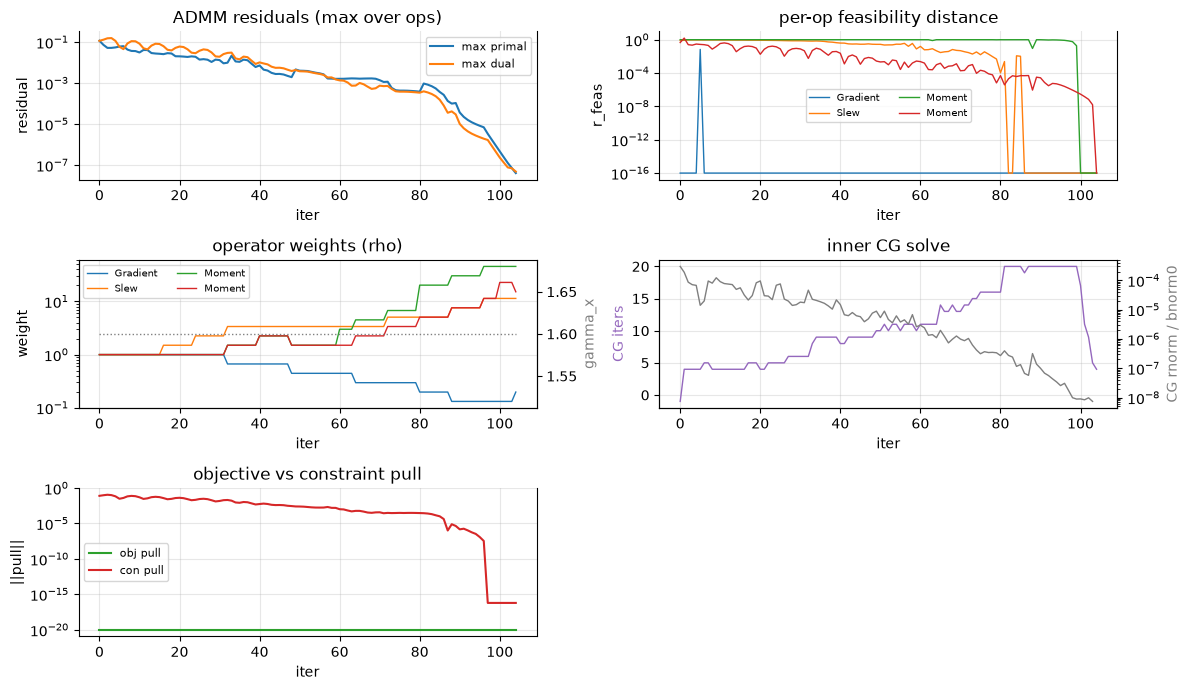

In [3]:
fig = plot_convergence(solver.get_debug(), op_names=gp.get_op_names(), figsize=(12, 7))

## Warm starts

`get_warmstart()` captures the returned iterate together with each operator's dual variable and weight, and
`set_warmstart()` seeds the next solve with it. Operators are matched by key (`gparams.get_op_keys()`), and
the snapshot is resampled when N changes, which makes it useful inside a search over durations or
parameters.

In [4]:
snapshot = solver.get_warmstart()
print('operators:', [op['key'] for op in snapshot['ops']])

for N, warm in ((140, False), (140, True), (150, False), (150, True)):
    s = gropt.SolverGroptSDMM()
    if warm:
        s.set_warmstart(snapshot)       # from the N = 140 solve
    t0 = timer()
    r = s.solve(flow_encode(N))
    print(f'N={N}  warm={warm!s:5}  converged={r.converged}  iterations={r.n_iter:4d}  '
          f'time={1e3 * (timer() - t0):.2f} ms')

operators: ['Gradient#0', 'Slew#0', 'Moment#0', 'Moment#1']
N=140  warm=False  converged=True  iterations= 104  time=2.33 ms
N=140  warm=True   converged=True  iterations=   2  time=0.05 ms
N=150  warm=False  converged=True  iterations=  84  time=1.57 ms
N=150  warm=True   converged=True  iterations=  41  time=0.91 ms


## OSQP

`SolverOSQP` is an alternative ADMM solver modelled on OSQP, with a single penalty parameter balanced from
the primal and dual residuals. It takes the same problem, which makes it a useful cross-check.

In [5]:
for solver in (gropt.SolverGroptSDMM(), gropt.SolverOSQP()):
    t0 = timer()
    r = solver.solve(flow_encode(140))
    print(f'{type(solver).__name__:16s} converged={r.converged}  iterations={r.n_iter:4d}  '
          f'time={1e3 * (timer() - t0):.2f} ms')

SolverGroptSDMM  converged=True  iterations= 104  time=2.37 ms
SolverOSQP       converged=True  iterations=  37  time=1.27 ms


## Logging

The C++ core logs through spdlog, at the warning level by default. In Jupyter its messages do not reach
the notebook unless forwarded: `gropt.setup_logging(level)` does that (in Jupyter) and sets the level, from
0 (trace) to 6 (off). Level 2 (info) prints a table of every constraint at the end of each solve, and 1
(debug) also one every `log_interval` iterations:

```python
gropt.setup_logging(2)
r = gropt.solve(gparams)
gropt.setup_logging(3)   # back to warnings only
```